1. Log Transformation hota kya hai?

Log transformation ek mathematical technique hai jo bade numerical values ko compress (chhota) karti hai.

Maths mein:

$$ y = \log(x) $$

Lekin Machine Learning mein hum aksar np.log1p(x) use karte hain:

$$ \boxed{y = \ln(1+x)} $$

Yahan ln ka matlab Natural Logarithm hai, jiska base \(e \approx 2.718\) hota hai.

Example: Maths se calculate karte hain

Maan lo tumhare paas car ke km_driven values hain:

Original x	Log Transformation ln(1+x)	Approx Output
0	ln(1+0)	0
1	ln(1+1)	0.693
10	ln(1+10)	2.398
100	ln(1+100)	4.615
1,000	ln(1+1000)	6.909
10,000	ln(1+10000)	9.210
100,000	ln(1+100000)	11.513

Notice karo: Original value 100,000 thi, lekin log transformation ke baad sirf 11.513 ho gayi.

Yaani values ka scale compress ho gaya.

2. Log transformation graphically kya karta hai?
5

Log function ki shuruaat mein values relatively tezi se badhti hain, lekin jaise-jaise x bada hota hai, output dheere-dheere badhta hai.

Isliye bahut bade values ka impact kam ho jata hai.

ML mein iska use aksar right-skewed data ko less skewed banane ke liye kiya jata hai.

Jaise car prices, house prices, income aur km_driven.

3. Ab Python mein np.log1p() kaise kaam karta hai?

Tumhara code:

from sklearn.preprocessing import FunctionTransformer
import numpy as np

trf = FunctionTransformer(func=np.log1p)

Yahan FunctionTransformer ko tumne ek mathematical function diya hai: np.log1p.

Jab tum ye karoge:

trf.transform([[0], [1], [10], [100], [1000]])

Toh internally har value par ye calculation hogi:

np.log1p(0)     # ln(1 + 0) = 0
np.log1p(1)     # ln(1 + 1) = 0.693
np.log1p(10)    # ln(1 + 10) = 2.398
np.log1p(100)   # ln(1 + 100) = 4.615
np.log1p(1000)  # ln(1 + 1000) = 6.909

Output:

[[0.        ],
 [0.69314718],
 [2.39789527],
 [4.61512052],
 [6.90875478]]

Important: np.log1p(x) mathematically np.log(1+x) ke equivalent hai, lekin numerical precision ke liye especially chhoti values par zyada accurate ho sakta hai.

4. np.log() aur np.log1p() mein difference
Function	Formula	x = 0 par
np.log(x)	ln(x)	-inf
np.log1p(x)	ln(1+x)	0

np.log(0) undefined hota hai, jabki np.log1p(0) valid hai.

Isliye jab data mein zero values ho sakti hain, tab log1p() convenient hota hai.

⚠️ Lekin np.log1p(x) ke liye bhi x > -1 hona chahiye. Negative values par ye har case mein valid nahi hai.

5. ML mein apply kaise karoge?

Maan lo tum km_driven column par log transformation apply karna chahte ho:

from sklearn.preprocessing import FunctionTransformer
import numpy as np

trf = FunctionTransformer(func=np.log1p)

x_train['km_driven'] = trf.transform(x_train[['km_driven']])

Lekin agar tum x_train aur x_test ko alag rakhkar kaam kar rahe ho, toh dono par same transformation apply karna.

Ek baat yaad rakhna: Log transformation normalization ya standardization nahi hai. Ye data ke distribution aur scale ko change karta hai. Iska main purpose right-skewness ko reduce karna aur large values ko compress karna ho sakta hai.

In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv('d:/Machine_learning/data/train.csv',usecols=['Age','Fare','Survived'])

In [3]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [4]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [14]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [15]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [16]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

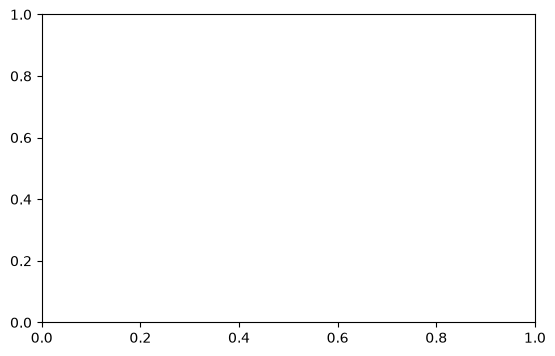

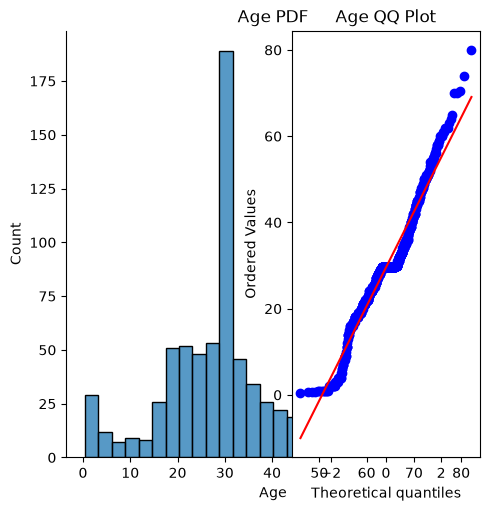

In [18]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.displot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

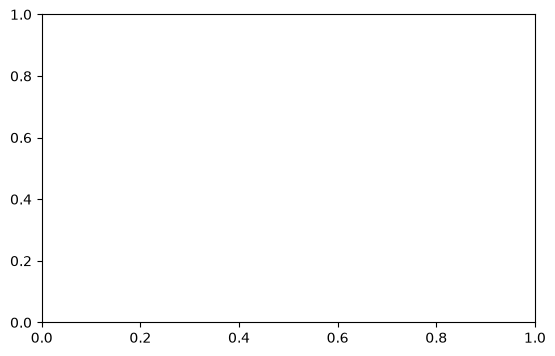

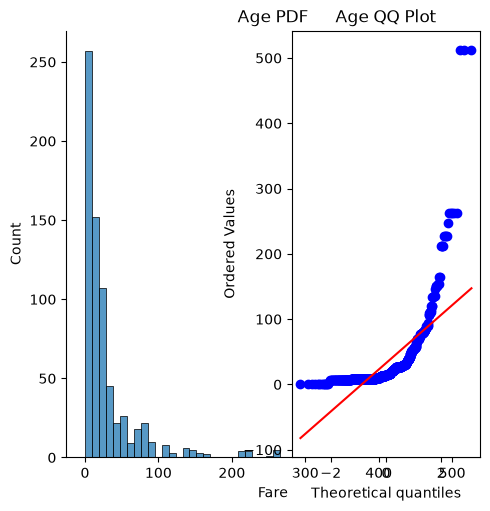

In [19]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.displot(X_train['Fare'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

In [20]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [21]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)
    
y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6759776536312849


In [22]:
trf = FunctionTransformer(func=np.log1p)

In [23]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [24]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)
    
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6871508379888268


In [25]:
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy',cv=10)))

LR 0.678027465667915
DT 0.6633208489388265


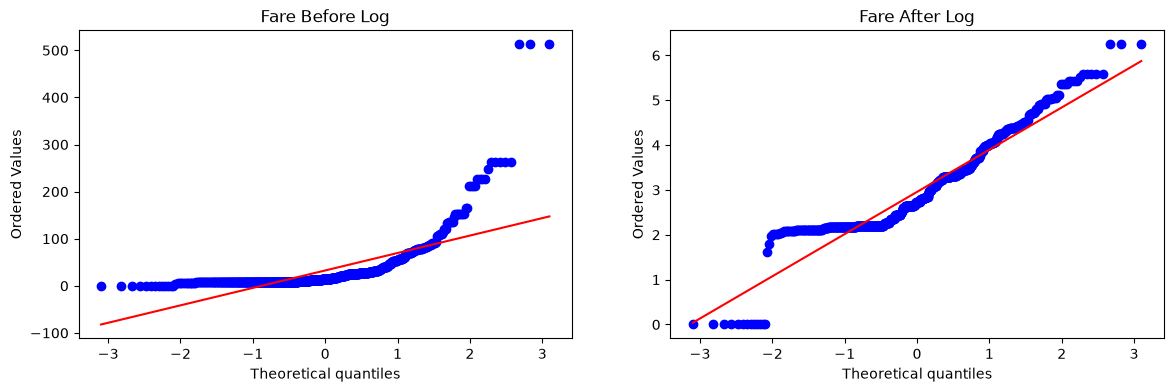

In [26]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

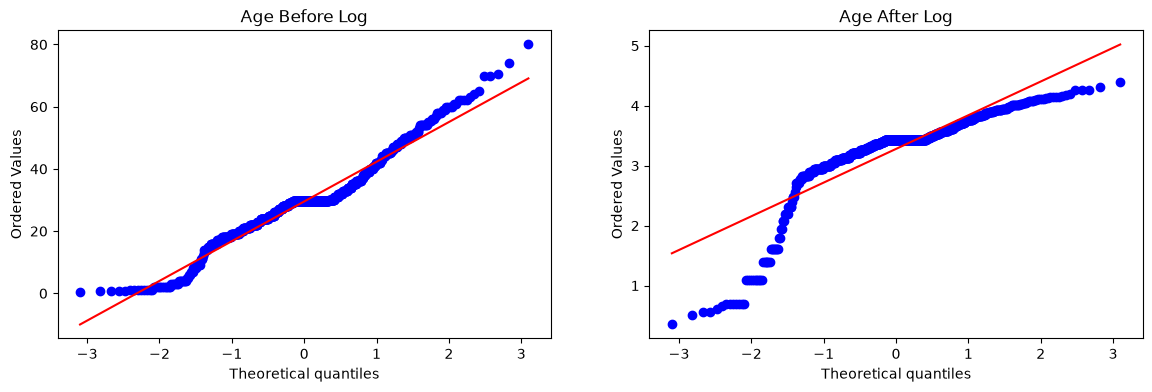

In [27]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log')

plt.show()

In [28]:
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [ ]:
clf = LogisticRegression()

clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2,y_train)

clf2.fit(X_train_transformed2,y_train)
    
y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.659217877094972


In [30]:
X_transformed2 = trf2.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed2,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed2,y,scoring='accuracy',cv=10)))

LR 0.6712609238451936
DT 0.6689263420724095


In [31]:
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()
    

Accuracy 0.6195131086142323


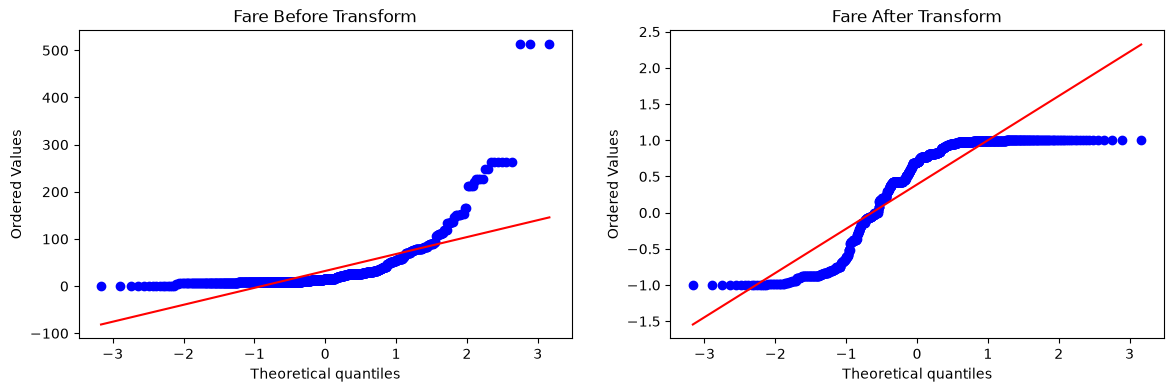

In [32]:
apply_transform(np.sin)